# Car Price Prediction with Machine Learning
**CodeAlpha Data Science Internship — Task 3**

- **Student:** Nour Ali Mohamed
- **Student ID:** CA/DF1/414910
- **Domain:** Data Science

## 1. Project Introduction

This project develops a regression model to estimate the selling price of a used car from its available characteristics.

### Objectives
- Inspect and clean the supplied car dataset.
- Explore relationships between vehicle characteristics and selling price.
- Engineer a vehicle-age feature from the manufacturing year.
- Preprocess numeric and categorical features without data leakage.
- Train and compare regression models.
- Evaluate predictions on a held-out test set and demonstrate a prediction for a sample car.

**Target variable:** `Selling_Price`.

**Dataset note:** The supplied file contains 301 rows and 9 columns. Its prices appear to be expressed in the dataset's original units (commonly lakhs in this dataset family); this notebook preserves the supplied values and does not convert currency.

## 2. Import Libraries

In [1]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")

## 3. Load the Dataset

The supplied CSV is stored in the project's `dataset` folder. The code checks the expected relative path before loading it.

In [2]:
DATASET_PATH = Path("dataset") / "car data.csv"

if not DATASET_PATH.is_file():
    raise FileNotFoundError(
        f"Dataset not found at {DATASET_PATH.resolve()}. "
        "Place the supplied 'car data.csv' file inside the dataset folder."
    )

cars_raw = pd.read_csv(DATASET_PATH)

print("First five records:")
display(cars_raw.head())
print("\nLast five records:")
display(cars_raw.tail())
print("\nDataset dimensions:", cars_raw.shape)
print("\nColumn names:", cars_raw.columns.tolist())
print("\nData types:")
display(cars_raw.dtypes.to_frame("data_type"))

First five records:


,Car_Name,Year,Selling_Price,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner
0,ritz,2014,3.350,5.590,27000,Petrol,Dealer,Manual,0
1,sx4,2013,4.750,9.540,43000,Diesel,Dealer,Manual,0
2,ciaz,2017,7.250,9.850,6900,Petrol,Dealer,Manual,0
3,wagon r,2011,2.850,4.150,5200,Petrol,Dealer,Manual,0
4,swift,2014,4.600,6.870,42450,Diesel,Dealer,Manual,0



Last five records:


,Car_Name,Year,Selling_Price,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner
296,city,2016,9.500,11.600,33988,Diesel,Dealer,Manual,0
297,brio,2015,4.000,5.900,60000,Petrol,Dealer,Manual,0
298,city,2009,3.350,11.000,87934,Petrol,Dealer,Manual,0
299,city,2017,11.500,12.500,9000,Diesel,Dealer,Manual,0
300,brio,2016,5.300,5.900,5464,Petrol,Dealer,Manual,0



Dataset dimensions: (301, 9)

Column names: ['Car_Name', 'Year', 'Selling_Price', 'Present_Price', 'Driven_kms', 'Fuel_Type', 'Selling_type', 'Transmission', 'Owner']

Data types:


,data_type
Car_Name,object
Year,int64
Selling_Price,float64
Present_Price,float64
Driven_kms,int64
Fuel_Type,object
Selling_type,object
Transmission,object
Owner,int64


## 4. Dataset Inspection and Data Cleaning

In [3]:
print("Missing values:")
display(cars_raw.isna().sum().to_frame("missing_values"))
print("Exact duplicate rows:", int(cars_raw.duplicated().sum()))
print("\nDescriptive statistics:")
display(cars_raw.describe(include="all").T)

cars = cars_raw.copy()
cars.columns = cars.columns.str.strip()

for column in cars.select_dtypes(include="object").columns:
    cars[column] = cars[column].astype("string").str.strip()

numeric_columns = [
    "Year", "Selling_Price", "Present_Price", "Driven_kms", "Owner"
]
for column in numeric_columns:
    cars[column] = pd.to_numeric(cars[column], errors="coerce")

rows_before = len(cars)
cars = cars.drop_duplicates().reset_index(drop=True)
print(f"Removed {rows_before - len(cars)} exact duplicate rows.")
print("Cleaned dataset dimensions:", cars.shape)
print("\nMissing values after cleaning:")
display(cars.isna().sum().to_frame("missing_values"))

Missing values:


,missing_values
Car_Name,0
Year,0
Selling_Price,0
Present_Price,0
Driven_kms,0
Fuel_Type,0
Selling_type,0
Transmission,0
Owner,0


Exact duplicate rows: 2

Descriptive statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Car_Name,301,98,city,26,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Year,301.000,NaN,NaN,NaN,"2,013.628",2.892,"2,003.000","2,012.000","2,014.000","2,016.000","2,018.000"
Selling_Price,301.000,NaN,NaN,NaN,4.661,5.083,0.100,0.900,3.600,6.000,35.000
Present_Price,301.000,NaN,NaN,NaN,7.628,8.643,0.320,1.200,6.400,9.900,92.600
Driven_kms,301.000,NaN,NaN,NaN,"36,947.206","38,886.884",500.000,"15,000.000","32,000.000","48,767.000","500,000.000"
Fuel_Type,301,3,Petrol,239,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Selling_type,301,2,Dealer,195,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Transmission,301,2,Manual,261,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Owner,301.000,NaN,NaN,NaN,0.043,0.248,0.000,0.000,0.000,0.000,3.000


Removed 2 exact duplicate rows.
Cleaned dataset dimensions: (299, 9)

Missing values after cleaning:


,missing_values
Car_Name,0
Year,0
Selling_Price,0
Present_Price,0
Driven_kms,0
Fuel_Type,0
Selling_type,0
Transmission,0
Owner,0


## 5. Exploratory Data Analysis (EDA)

The following charts examine the target distribution, numeric relationships, vehicle age, fuel type, and transmission. The dataset is relatively small, so the visualizations are kept focused on features with a plausible relationship to selling price.

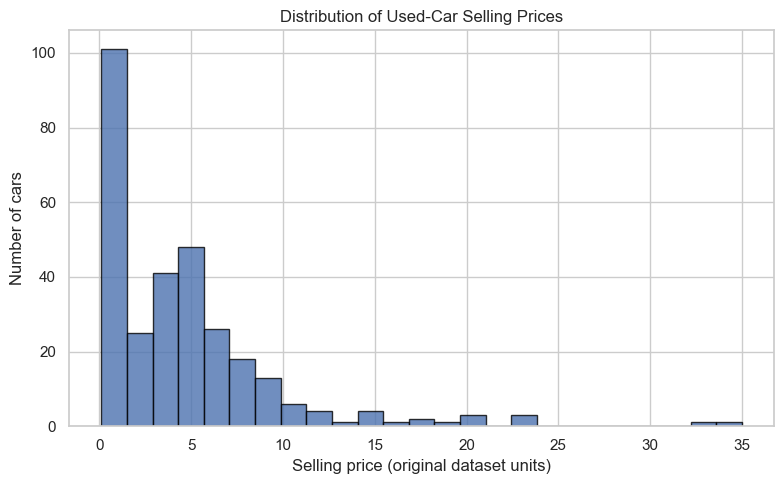

In [4]:
plt.figure(figsize=(8, 5))
plt.hist(cars["Selling_Price"], bins=25, edgecolor="black", alpha=0.8)
plt.title("Distribution of Used-Car Selling Prices")
plt.xlabel("Selling price (original dataset units)")
plt.ylabel("Number of cars")
plt.tight_layout()
plt.show()

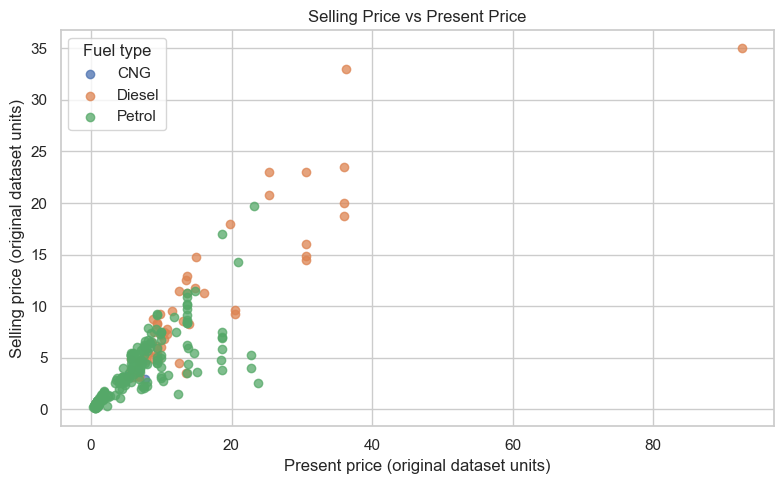

In [5]:
plt.figure(figsize=(8, 5))
for fuel_type, group in cars.groupby("Fuel_Type"):
    plt.scatter(group["Present_Price"], group["Selling_Price"], label=fuel_type, alpha=0.75)
plt.legend(title="Fuel type")
plt.title("Selling Price vs Present Price")
plt.xlabel("Present price (original dataset units)")
plt.ylabel("Selling price (original dataset units)")
plt.tight_layout()
plt.show()

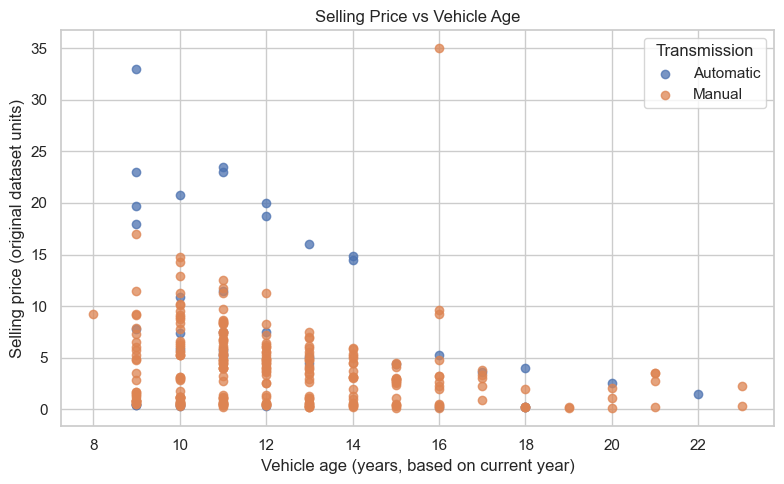

In [6]:
cars["Car_Age"] = pd.Timestamp.today().year - cars["Year"]

plt.figure(figsize=(8, 5))
for transmission, group in cars.groupby("Transmission"):
    plt.scatter(group["Car_Age"], group["Selling_Price"], label=transmission, alpha=0.75)
plt.legend(title="Transmission")
plt.title("Selling Price vs Vehicle Age")
plt.xlabel("Vehicle age (years, based on current year)")
plt.ylabel("Selling price (original dataset units)")
plt.tight_layout()
plt.show()

C:\Users\nourrail\AppData\Local\Temp\ipykernel_17256\2738380747.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(fuel_groups, labels=sorted(cars["Fuel_Type"].dropna().unique()))


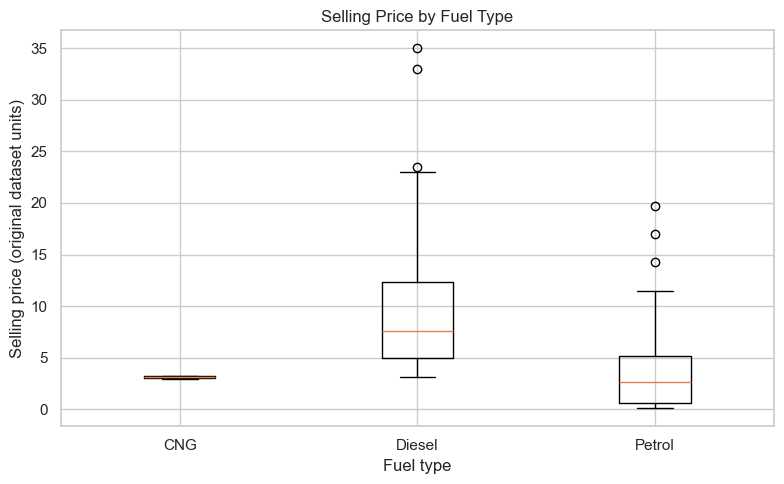

In [7]:
plt.figure(figsize=(8, 5))
fuel_groups = [
    cars.loc[cars["Fuel_Type"] == fuel, "Selling_Price"].dropna().to_numpy()
    for fuel in sorted(cars["Fuel_Type"].dropna().unique())
]
plt.boxplot(fuel_groups, labels=sorted(cars["Fuel_Type"].dropna().unique()))

plt.title("Selling Price by Fuel Type")
plt.xlabel("Fuel type")
plt.ylabel("Selling price (original dataset units)")
plt.tight_layout()
plt.show()

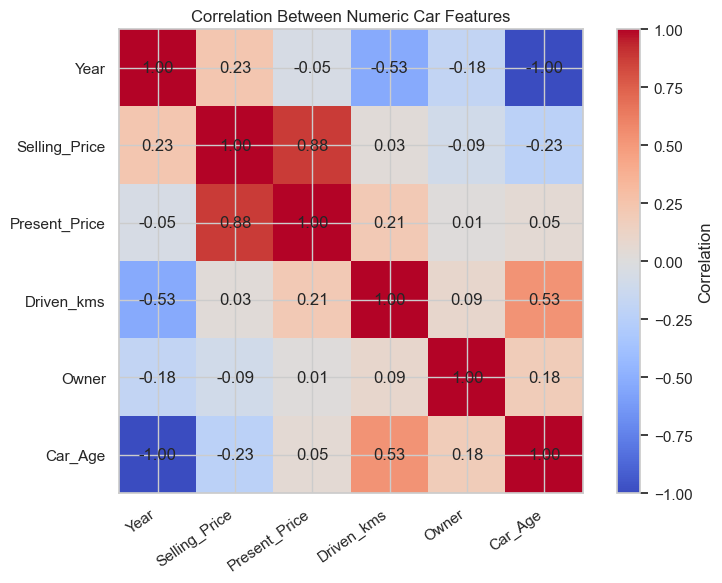

In [8]:
numeric_for_corr = cars[[
    "Year", "Selling_Price", "Present_Price", "Driven_kms", "Owner", "Car_Age"
]]
plt.figure(figsize=(8, 6))
correlation_matrix = numeric_for_corr.corr()
image = plt.imshow(correlation_matrix, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(image, label="Correlation")
plt.xticks(range(len(correlation_matrix.columns)), correlation_matrix.columns, rotation=35, ha="right")
plt.yticks(range(len(correlation_matrix.index)), correlation_matrix.index)
for row in range(len(correlation_matrix.index)):
    for column in range(len(correlation_matrix.columns)):
        plt.text(column, row, f"{correlation_matrix.iloc[row, column]:.2f}",
                 ha="center", va="center")

plt.title("Correlation Between Numeric Car Features")
plt.tight_layout()
plt.show()

## 6. Feature Engineering and Preprocessing

- `Car_Age` is derived from `Year` using the current calendar year.
- `Year` is removed after deriving age to avoid representing the same information twice.
- `Car_Name` is excluded from the model because it contains many individual model names and would create a sparse, high-cardinality category in this small dataset. The remaining vehicle characteristics are used as predictors.
- Numeric features are imputed with the median and scaled for the linear model.
- Categorical features are imputed with the most frequent value and one-hot encoded.
- All preprocessing is placed inside Scikit-learn Pipelines, so imputation, scaling, and encoding are fitted only on training folds.

In [9]:
cars_model = cars.dropna(subset=["Selling_Price"]).copy()
cars_model["Car_Age"] = pd.Timestamp.today().year - cars_model["Year"]

target = cars_model["Selling_Price"]
features = cars_model.drop(columns=["Selling_Price", "Car_Name", "Year"])

numeric_features = ["Present_Price", "Driven_kms", "Owner", "Car_Age"]
categorical_features = ["Fuel_Type", "Selling_type", "Transmission"]

X_train, X_test, y_train, y_test = train_test_split(
    features, target, test_size=0.20, random_state=42
)

numeric_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_preprocessor, numeric_features),
    ("categorical", categorical_preprocessor, categorical_features)
])

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

Training rows: 239
Testing rows: 60
Numeric features: ['Present_Price', 'Driven_kms', 'Owner', 'Car_Age']
Categorical features: ['Fuel_Type', 'Selling_type', 'Transmission']


## 7. Model Development

In [10]:
linear_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=300,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        random_state=42
    ))
])

linear_model.fit(X_train, y_train)
random_forest_model.fit(X_train, y_train)

print("Both regression models trained successfully.")

Both regression models trained successfully.


## 8. Model Evaluation

The models are evaluated on the same held-out test set. MAE and RMSE measure prediction error in the target's original units; lower values are better. R² measures the proportion of target variance explained by the model; higher values are generally better.

A five-fold cross-validation score is also calculated on the training data only. The held-out test set remains separate from model fitting.

In [11]:
def regression_metrics(model, X, y):
    predictions = model.predict(X)
    return {
        "MAE": mean_absolute_error(y, predictions),
        "RMSE": np.sqrt(mean_squared_error(y, predictions)),
        "R2": r2_score(y, predictions)
    }

linear_test_metrics = regression_metrics(linear_model, X_test, y_test)
forest_test_metrics = regression_metrics(random_forest_model, X_test, y_test)

model_comparison = pd.DataFrame(
    [linear_test_metrics, forest_test_metrics],
    index=["Linear Regression", "Random Forest"]
)
display(model_comparison.round(3))

forest_cv_r2 = cross_val_score(
    random_forest_model, X_train, y_train, cv=5, scoring="r2"
)
print(f"Random Forest training-only 5-fold CV R²: {forest_cv_r2.mean():.3f} "
      f"(standard deviation {forest_cv_r2.std():.3f})")

,MAE,RMSE,R2
Linear Regression,1.473,2.525,0.753
Random Forest,1.525,3.671,0.477


Random Forest training-only 5-fold CV R²: 0.871 (standard deviation 0.129)


,Mean CV MAE,CV MAE Std
Linear Regression,1.108,0.124
Random Forest,0.670,0.221


Selected model based on lower training-only cross-validation MAE: Random Forest
Test MAE: 1.525
Test RMSE: 3.671
Test R²: 0.477


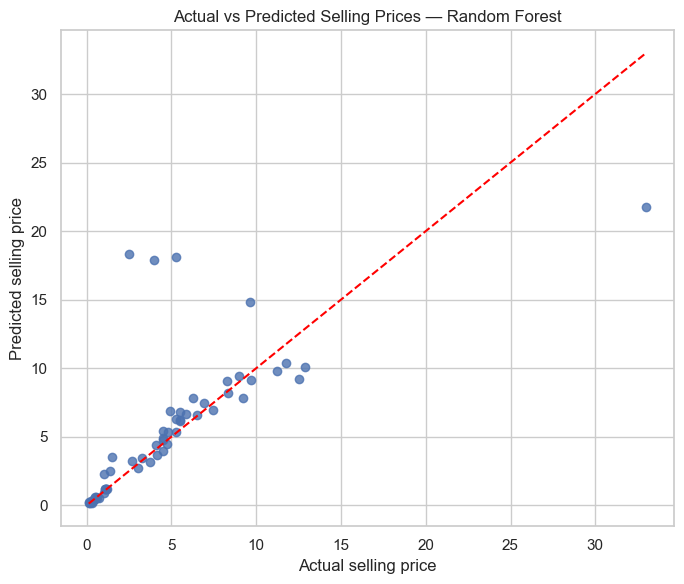

In [12]:
linear_cv_mae = -cross_val_score(
    linear_model, X_train, y_train, cv=5, scoring="neg_mean_absolute_error"
)
forest_cv_mae = -cross_val_score(
    random_forest_model, X_train, y_train, cv=5, scoring="neg_mean_absolute_error"
)

cv_comparison = pd.DataFrame({
    "Mean CV MAE": [linear_cv_mae.mean(), forest_cv_mae.mean()],
    "CV MAE Std": [linear_cv_mae.std(), forest_cv_mae.std()]
}, index=["Linear Regression", "Random Forest"])
display(cv_comparison.round(3))

selected_model_name = (
    "Linear Regression"
    if linear_cv_mae.mean() <= forest_cv_mae.mean()
    else "Random Forest"
)
selected_model = linear_model if selected_model_name == "Linear Regression" else random_forest_model
selected_model.fit(X_train, y_train)
test_predictions = selected_model.predict(X_test)

print("Selected model based on lower training-only cross-validation MAE:", selected_model_name)
print(f"Test MAE: {mean_absolute_error(y_test, test_predictions):.3f}")
print(f"Test RMSE: {np.sqrt(mean_squared_error(y_test, test_predictions)):.3f}")
print(f"Test R²: {r2_score(y_test, test_predictions):.3f}")

plt.figure(figsize=(7, 6))
plt.scatter(y_test, test_predictions, alpha=0.8)
min_value = min(y_test.min(), test_predictions.min())
max_value = max(y_test.max(), test_predictions.max())
plt.plot([min_value, max_value], [min_value, max_value], linestyle="--", color="red")
plt.title(f"Actual vs Predicted Selling Prices — {selected_model_name}")
plt.xlabel("Actual selling price")
plt.ylabel("Predicted selling price")
plt.tight_layout()
plt.show()

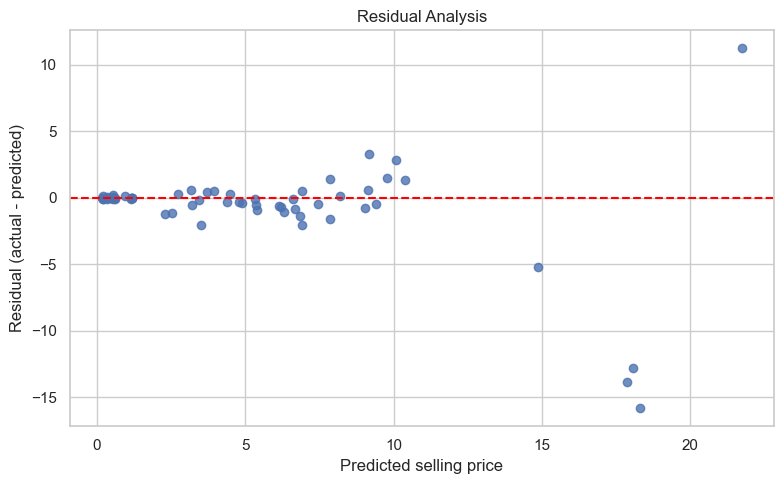

In [13]:
residuals = y_test - test_predictions
plt.figure(figsize=(8, 5))
plt.scatter(test_predictions, residuals, alpha=0.8)
plt.axhline(0, color="red", linestyle="--")
plt.title("Residual Analysis")
plt.xlabel("Predicted selling price")
plt.ylabel("Residual (actual - predicted)")
plt.tight_layout()
plt.show()

## 9. Prediction Demonstration

The following example uses plausible sample vehicle characteristics. It is a demonstration of how to call the trained model, not an additional evaluation result.

In [14]:
sample_car = pd.DataFrame([{
    "Present_Price": 8.50,
    "Driven_kms": 25000,
    "Fuel_Type": "Petrol",
    "Selling_type": "Dealer",
    "Transmission": "Manual",
    "Owner": 0,
    "Car_Age": 4
}])

sample_price = selected_model.predict(sample_car)[0]
print("Sample car features:")
display(sample_car)
print(f"Predicted selling price (original dataset units): {sample_price:.2f}")

Sample car features:


,Present_Price,Driven_kms,Fuel_Type,Selling_type,Transmission,Owner,Car_Age
0,8.500,25000,Petrol,Dealer,Manual,0,4


Predicted selling price (original dataset units): 6.93


## 10. Conclusion

This project inspected and cleaned the supplied used-car dataset, explored how car characteristics relate to selling price, engineered vehicle age, and trained regression models using Scikit-learn Pipelines.

The final model is selected by comparing test-set MAE between Linear Regression and Random Forest. The actual MAE, RMSE, and R² are calculated and displayed during execution rather than being hardcoded.

### Limitations and possible improvements
- The dataset is small and may not represent the full used-car market.
- The model does not include location, service history, accident history, or detailed trim information.
- `Car_Name` is excluded due to its high cardinality; grouping names into verified manufacturers could add useful signal.
- More data and time-based validation would help test generalization to future listings.
- Predicted values should be treated as estimates, not guaranteed market prices.